#Smiling or Not — Binary Facial Expression Classification
**Author:** Maximilien Muller  
**Course:** IA et Deep Learning — ESIEE Paris 2025-2026



## Objective
The goal of this project is to build a **Convolutional Neural Network (CNN)** capable of determining whether a person is smiling or not in a facial photograph. This is a **binary image classification** problem: `smile` vs `non_smile`.

## Pipeline Overview
1. Environment cleanup
2. Dataset download (Kaggle)
3. Train / Validation split
4. Data augmentation & generators
5. CNN architecture
6. Training
7. Results & analysis
8. Prediction on a real photo


## Step 1 : Environment Cleanup

Google Colab resets its file system between sessions, but sometimes old folders from a previous run persist in memory. To ensure a clean and reproducible environment, we start by deleting all previously created directories (`raw`, `dataset`, `train`, `val`) and any duplicate Kaggle credential files or zip archives.

In [2]:
import shutil, os

# Delete all folders created in previous runs to avoid conflicts
for d in ['raw', 'dataset', 'train', 'val']:
    if os.path.exists(f'/content/{d}'):
        shutil.rmtree(f'/content/{d}')

# Remove any leftover zip files or duplicate Kaggle credential files
for f in os.listdir('/content'):
    if f.endswith('.zip') or 'Kaggle' in f or 'kaggle' in f:
        os.remove(f'/content/{f}')

print("Cleanup done")

Cleanup done



## Step 2 : Dataset Download

We use the **Smiling or Not Face Data** dataset, publicly available on [Kaggle](https://www.kaggle.com/datasets/chazzer/smiling-or-not-face-data).

## Dataset
Download the dataset from Kaggle: https://www.kaggle.com/datasets/chazzer/smiling-or-not-face-data

> Note: You will need a Kaggle account and your own `kaggle.json` credentials file to run the download cell.

### Setup
To access Kaggle's API, we upload a `kaggle.json` credentials file. Since Colab sometimes saves the file with a different name (e.g. `Kaggle Settings.json`), we automatically rename any file containing 'aggle' to `kaggle.json` to avoid errors.

### Dataset composition
After extraction, the dataset contains:
- **600 smile** images
- **603 non_smile** images
- A `test/` folder with 12,030 unlabeled images — **excluded from training**

The near-equal class balance ensures the model won't be biased toward predicting one class over the other.

In [3]:
# Global imports used throughout the notebook
import os, shutil, random, zipfile
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload Kag
gle credentials file (kaggle.json)
files.upload()

# Rename the uploaded file to kaggle.json regardless of its original name
for f in os.listdir('/content'):
    if 'aggle' in f:
        os.rename(f'/content/{f}', '/content/kaggle.json')
        break

# Place credentials in the expected Kaggle config directory
os.makedirs('/root/.kaggle', exist_ok=True)
os.system('cp kaggle.json /root/.kaggle/')
os.system('chmod 600 /root/.kaggle/kaggle.json')
os.system('pip install -q kaggle')

# Download and extract the dataset
os.system('kaggle datasets download -d chazzer/smiling-or-not-face-data')

with zipfile.ZipFile('smiling-or-not-face-data.zip', 'r') as z:
    z.extractall('/content/raw')

# Display class distribution to verify balance
smile_count     = len(os.listdir('/content/raw/smile'))
non_smile_count = len(os.listdir('/content/raw/non_smile'))

print(f"smile     : {smile_count}")
print(f"non_smile : {non_smile_count}")
print(f"Total     : {smile_count + non_smile_count}")

Saving Kaggle.json to Kaggle.json
smile     : 600
non_smile : 603
Total     : 1203



## Step 3 : Train / Validation Split

We split the dataset into **80% training** and **20% validation** by manually copying files into separate directories.

### Why manual split?
Keras's built-in `validation_split` parameter in `flow_from_directory` can produce **inconsistent splits** when used with two separate generator instances. By physically separating the files into `/content/train/` and `/content/val/`, we guarantee that:
- The same images never appear in both sets
- The split is **reproducible** (fixed `seed=42`)
- Training augmentation and validation normalization are applied independently

This gives us approximately **962 training images** and **241 validation images**.

In [4]:
# Create destination directories for each class in train and val
for d in ['train/smile', 'train/non_smile', 'val/smile', 'val/non_smile']:
    os.makedirs(f'/content/{d}', exist_ok=True)

def split_class(src, train_dst, val_dst, val_ratio=0.2, seed=42):
    """
    Splits images from a source directory into train and validation sets.
    - val_ratio: proportion of images reserved for validation (default 20%)
    - seed: fixed random seed for reproducibility
    """
    imgs = os.listdir(src)
    random.seed(seed)
    random.shuffle(imgs)
    cut = int(len(imgs) * (1 - val_ratio))
    for f in imgs[:cut]:
        shutil.copy(os.path.join(src, f), os.path.join(train_dst, f))
    for f in imgs[cut:]:
        shutil.copy(os.path.join(src, f), os.path.join(val_dst, f))

split_class('/content/raw/smile',     '/content/train/smile',     '/content/val/smile')
split_class('/content/raw/non_smile', '/content/train/non_smile', '/content/val/non_smile')

print("Train smile    : ", len(os.listdir('/content/train/smile')))
print("Train non_smile: ", len(os.listdir('/content/train/non_smile')))
print("Val smile      : ", len(os.listdir('/content/val/smile')))
print("Val non_smile  : ", len(os.listdir('/content/val/non_smile')))

Train smile    :  480
Train non_smile:  482
Val smile      :  120
Val non_smile  :  121



## Step 4 : Data Augmentation & Generators

### Why data augmentation?
With only ~960 training images, a CNN trained from scratch is at high risk of overfitting, memorizing the training data rather than learning general features. Data augmentation artificially increases the diversity of the training set by applying random transformations to each image at every epoch:

| Transformation | Value | Effect |
|---|---|---|
| `rescale` | 1./255 | Normalize pixel values to [0, 1] |
| `rotation_range` | 20° | Random rotation |
| `width/height_shift` | 10% | Random translation |
| `zoom_range` | 10% | Random zoom |
| `horizontal_flip` | True | Mirror the image |

### Important
Augmentation is applied only to training images. The validation generator only rescales pixel values no random transformations to ensure evaluation is unbiased and consistent.

In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Training generator: augmentation + normalization
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)


train_generator = train_datagen.flow_from_directory(
    '/content/train',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    classes=['non_smile', 'smile']
)


validation_generator = val_datagen.flow_from_directory(
    '/content/val',
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    classes=['non_smile', 'smile'],
    shuffle=False
)

Found 962 images belonging to 2 classes.
Found 241 images belonging to 2 classes.



## Step 5 — CNN Architecture

We design a **Convolutional Neural Network (CNN)** from scratch. CNNs are the standard architecture for image classification because they learn spatial features (edges, textures, shapes) through convolutional filters — exactly what is needed for facial expression detection.

### Architecture
The model has **3 convolutional blocks** followed by fully connected layers:

| Layer | Role |
|---|---|
| `Conv2D` | Extracts spatial features (edges, textures) |
| `BatchNormalization` | Stabilizes and accelerates training |
| `MaxPooling2D` | Reduces spatial dimensions (halves width/height) |
| `Dropout` | Randomly disables neurons → prevents overfitting |

Filters increase progressively: **32 → 64 → 128** so the network learns increasingly complex features at each level.

### Output layer
A single **sigmoid** neuron outputs a probability between 0 and 1:
- Close to **0** → non_smile
- Close to **1** → smile

### Regularization choices
- **Dropout 0.25** in blocks 1 & 2 (lighter regularization in early layers)
- **Dropout 0.4** in block 3 (stronger regularization before the dense layer)
- **Dropout 0.5** before the final dense layer
- `clear_session()` prevents parameter accumulation from previous model definitions

In [6]:
import tensorflow as tf
from keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tf.keras.backend.clear_session()

model = models.Sequential()

# Block_1
model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(64,64,3)))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Dropout(0.25))

# Block_2
model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Dropout(0.25))

# Block_3
model.add(layers.Conv2D(128, (3,3), activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Dropout(0.4))

model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(1, activation='sigmoid'))

model.compile(
    loss='binary_crossentropy',
    optimizer=optimizers.Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,274,305 (4.86 MB)

 Trainable params: 1,273,857 (4.86 MB)

 Non-trainable params: 448 (1.75 KB)


## Step 6 — Training

We train the model for **40 epochs** with a `ModelCheckpoint` callback that automatically saves the **best version** of the model based on validation accuracy. This ensures we always keep the optimal weights even if the last epoch is not the best.

We chose not to use `EarlyStopping` in order to observe the complete learning curve over 40 epochs.

In [7]:

callbacks = [
    ModelCheckpoint(
        'best_model.keras',
        monitor='val_accuracy',
        save_best_only=True
    )
]

history = model.fit(
    train_generator,
    epochs=40,
    validation_data=validation_generator,
    callbacks=callbacks
)

Epoch 1/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 20s 538ms/step - accuracy: 0.5322 - loss: 1.2081 - val_accuracy: 0.4979 - val_loss: 0.6840
Epoch 2/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 413ms/step - accuracy: 0.6351 - loss: 0.9216 - val_accuracy: 0.7552 - val_loss: 0.6562
Epoch 3/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 12s 407ms/step - accuracy: 0.7183 - loss: 0.6576 - val_accuracy: 0.5602 - val_loss: 0.6538
Epoch 4/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 21s 411ms/step - accuracy: 0.7235 - loss: 0.5753 - val_accuracy: 0.5062 - val_loss: 0.6777
Epoch 5/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 12s 382ms/step - accuracy: 0.7484 - loss: 0.5825 - val_accuracy: 0.5021 - val_loss: 0.8379
Epoch 6/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 369ms/step - accuracy: 0.7672 - loss: 0.5172 - val_accuracy: 0.5104 - val_loss: 0.7990
Epoch 7/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 365ms/step - accuracy: 0.7963 - loss: 0.4696 - val_accuracy: 0.5104 - val_loss: 0.9866
Epoch 8/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 360ms/step - accuracy: 0.7817 - loss: 0.4913 - val_accu


## Step 7 — Results & Analysis

### Learning curves
We plot accuracy and loss curves for both the training and validation sets to evaluate model performance and detect potential overfitting.

**What to look for:**
- Both curves increasing together → the model is learning correctly
- Val accuracy ≥ Train accuracy → expected due to Dropout (disabled during validation)
- Both losses converging → no overfitting
- Training loss ↓ while validation loss ↑ → overfitting

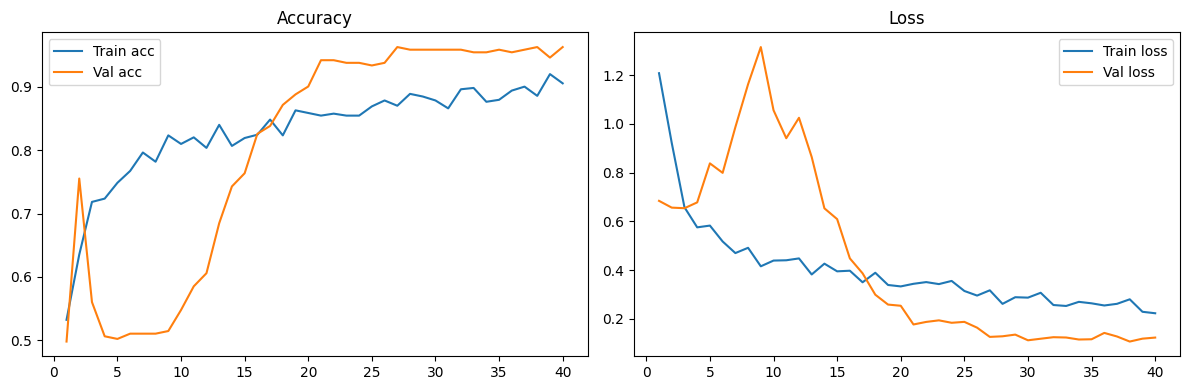

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.9627 - loss: 0.1227
Val accuracy : 0.9627


In [8]:
# Extract training history metrics
acc      = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss     = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Train acc')
plt.plot(epochs_range, val_acc, label='Val acc')
plt.title('Accuracy')
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Train loss')
plt.plot(epochs_range, val_loss, label='Val loss')
plt.title('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Final evaluation on the full validation set
val_loss_score, val_acc_score = model.evaluate(validation_generator)
print(f"Val accuracy : {val_acc_score:.4f}")


## Step 8 — Prediction on a Real Photo

We test the model on a real photograph to verify it generalizes beyond the training data.

The image is:
1. Uploaded from the local machine
2. Resized to **64×64 pixels** (same as training)
3. Normalized (pixel values divided by 255)
4. Expanded to shape `(1, 64, 64, 3)` — the model expects a batch, not a single image

The model outputs a score between 0 and 1:
- **> 0.5** → smiling
- **≤ 0.5** → not smiling

In [9]:
from keras.utils import load_img, img_to_array

# Upload a face photo
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# resize to 64x64 and normalize pixel values
img = load_img(img_path, target_size=(64, 64))
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

# Run prediction
prediction = model.predict(img_array)[0][0]

# Display the image
plt.imshow(load_img(img_path, target_size=(64, 64)))
plt.axis('off')
plt.show()

# Output the result
print(f"Score : {prediction:.4f}")
print("Prediction : smiling " if prediction > 0.5 else "Prediction : not smiling ")

Saving face_photo.jpg to face_photo.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step


Score : 0.9662
Prediction : smiling 
